# Exercise 2: Is this non-coding variant oncogenic?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/BigMindLab/Tutorial_IA_ISCB-LATAM_2026/blob/dev/modules/M02_multiomics_alphagenome/notebooks/score_variant_TAL1.ipynb)

**Time:** about 12 minutes with precomputed results; first-time live generation
and reference downloads can take longer. **Genome:** GRCh38/hg38.
**Client:** AlphaGenome 0.10.0. Run `setup.ipynb` first, then run all cells here
in a fresh kernel. Variables are not shared between notebooks.

We will test whether the Jurkat TAL1 enhancer insertion produces predictions
consistent with a regulatory gain of function. A predicted regulatory effect
does not by itself establish oncogenicity.

| Activity | Minutes |
| --- | ---: |
| Define the variant and inspect REF/ALT differences | 4 |
| Read scores and compare length-matched random insertions | 3 |
| Inspect local mutagenesis and discuss the mechanism | 3 |
| Try a second reported variant | 2 |

The sequence variant comes from **Jurkat**, but the main prediction context is
**CD34-positive common myeloid progenitor** (`CL:0001059`), following the official
TAL1 workflow. We also inspect **liver** (`UBERON:0002107`). These predictions are
not measurements in Jurkat and do not recreate its leukemia-specific state.
Actual returned tracks are checked below; missing coverage must not be read as zero.

## 1. Initialize this notebook

The environment discovery and Colab setup follow Exercise 1. The shared helper
reads the API key from secrets without writing it into notebook outputs.

In [1]:
import importlib.util
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/BigMindLab/Tutorial_IA_ISCB-LATAM_2026"
REPO_REF = "dev"

MODULE_RELATIVE_PATH = Path("modules/M02_multiomics_alphagenome")

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Find the module from the current directory or its parents.
MODULE_DIR = None

for parent in (Path.cwd(), *Path.cwd().parents):
    for candidate in (parent, parent / MODULE_RELATIVE_PATH):
        if (candidate / "utils" / "ag_helpers.py").is_file():
            MODULE_DIR = candidate.resolve()
            break
    if MODULE_DIR is not None:
        break

# Colab may have opened only the notebook, without the repository files.
if MODULE_DIR is None:
    if not IN_COLAB:
        raise FileNotFoundError(
            "Workshop files not found. Open this notebook inside "
            "the workshop repository."
        )

    checkout = Path("/content/alphagenome-workshop")

    if not checkout.exists():
        subprocess.run(
            [
                "git", "clone", "--depth", "1",
                "--branch", REPO_REF,
                REPO_URL, str(checkout),
            ],
            check=True,
        )

    MODULE_DIR = (checkout / MODULE_RELATIVE_PATH).resolve()

if not (MODULE_DIR / "utils" / "ag_helpers.py").is_file():
    raise FileNotFoundError(
        "ag_helpers.py was not found in the selected repository checkout. "
        "Check REPO_REF and the repository structure."
    )

print("Environment:", "Google Colab" if IN_COLAB else "Local / Codespaces")
print("Module directory:", MODULE_DIR)

if IN_COLAB:
    subprocess.run(
        [
            sys.executable, "-m", "pip", "install", "--quiet",
            "alphagenome==0.10.0", "pyarrow",  # same pin as requirements.txt
        ],
        check=True,
    )
    print("Colab dependencies installed.")
else:
    missing = [
        name
        for name in ("alphagenome", "pyarrow")
        if importlib.util.find_spec(name) is None
    ]

    if missing:
        raise RuntimeError(
            "Missing packages: "
            + ", ".join(missing)
            + ". Select the workshop Python kernel. "
            "If the problem persists, check the Codespaces environment."
        )

    print("Using the existing workshop environment.")

Environment: Local / Codespaces
Module directory: /workspaces/Tutorial_IA_ISCB-LATAM_2026/modules/M02_multiomics_alphagenome
Using the existing workshop environment.


In [2]:
import hashlib
import json
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from alphagenome.data import gene_annotation, genome, track_data
from alphagenome.data import transcript as transcript_utils
from alphagenome.models import dna_client, variant_scorers
from alphagenome.visualization import plot_components

utils_dir = str(MODULE_DIR / "utils")
if utils_dir not in sys.path:
    sys.path.insert(0, utils_dir)
import ag_helpers

CLIENT_VERSION = version("alphagenome")
if CLIENT_VERSION != "0.10.0":
    raise RuntimeError("Select the workshop kernel with alphagenome==0.10.0.")
model = ag_helpers.get_client(prompt=False)
print("AlphaGenome:", CLIENT_VERSION)
print("Shared helper:", ag_helpers.__file__)
print("Client configured:", model is not None)

/home/vscode/.local/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Live mode: requests go to the AlphaGenome API (the key is checked on the first one).
AlphaGenome: 0.10.0
Shared helper: /workspaces/Tutorial_IA_ISCB-LATAM_2026/modules/M02_multiomics_alphagenome/utils/ag_helpers.py
Client configured: True


## 2. Define the variant and a reproducible comparison

VCF positions are **1-based**; `genome.Interval` uses **0-based, half-open**
coordinates. Jurkat is `chr1:47239296 C>CCGTTTCCTAACC` in hg38. The first `C`
is the retained VCF anchor: **12 bases are inserted**, not 13.

Background controls preserve the anchor, site and insertion length. They are
uniform random DNA, not experimentally established benign variants, and are
not matched for GC content or dinucleotide composition. Twenty controls give
only a coarse rank. The seed and accepted sequence order are deterministic.

In [3]:
SAVE_PRECOMPUTED = False
N_BACKGROUND = 20
BACKGROUND_SEED = 42
CONTEXTS = ["CL:0001059", "UBERON:0002107"]
RANK_CONTEXT = "CL:0001059"

variant = genome.Variant(
    chromosome="chr1", position=47_239_296,
    reference_bases="C", alternate_bases="CCGTTTCCTAACC", name="Jurkat",
)
assert variant.alternate_bases.startswith(variant.reference_bases)
INSERTED = variant.alternate_bases[len(variant.reference_bases):]
assert len(INSERTED) == 12

def interval_spec(value):
    return {"chromosome": str(value.chromosome), "start": int(value.start),
            "end": int(value.end), "strand": str(value.strand), "name": value.name}

def variant_spec(value):
    return {key: getattr(value, key) for key in
            ("chromosome", "position", "reference_bases", "alternate_bases", "name")}

def result_name(label, request, prefix="ex2"):
    digest = hashlib.sha256(json.dumps(request, sort_keys=True).encode()).hexdigest()[:16]
    return f"{prefix}_{label}_{digest}"

def cached_bundle(label, request, make_data):
    name = result_name(label, request)
    result = ag_helpers.cached_call(
        name, lambda: {"request": request, "data": make_data()},
        save=SAVE_PRECOMPUTED,
    )
    if result["request"] != request:
        raise ValueError(f"Cached request mismatch: {name}")
    return result["data"]

def random_insertions(real_variant, count, seed):
    ref = real_variant.reference_bases
    inserted = real_variant.alternate_bases[len(ref):]
    if not real_variant.alternate_bases.startswith(ref) or not inserted:
        raise ValueError("This background generator requires an anchored pure insertion.")
    if not 1 <= count <= min(1000, 4 ** len(inserted) - 1):
        raise ValueError("Choose a feasible background size between 1 and 1000.")
    rng = np.random.default_rng(seed)
    seen = {inserted}
    backgrounds = []
    while len(backgrounds) < count:
        candidate = "".join(rng.choice(list("ACGT"), size=len(inserted)))
        if candidate in seen:
            continue
        seen.add(candidate)
        backgrounds.append(genome.Variant(
            real_variant.chromosome, real_variant.position, ref, ref + candidate,
            name=f"background_{len(backgrounds) + 1:02d}",
        ))
    return backgrounds

background_variants = random_insertions(variant, N_BACKGROUND, BACKGROUND_SEED)
display(pd.DataFrame([variant_spec(v) for v in [variant, *background_variants]]))

,chromosome,position,reference_bases,alternate_bases,name
0,chr1,47239296,C,CCGTTTCCTAACC,Jurkat
1,chr1,47239296,C,CATGCCTAGAAGT,background_01
2,chr1,47239296,C,CGTGTGATCGCAT,background_02
3,chr1,47239296,C,CTGCTGCCAAGTA,background_03
4,chr1,47239296,C,CTTCGATGCATCT,background_04
5,chr1,47239296,C,CGTTACCCAGAGG,background_05
6,chr1,47239296,C,CTGCTCCTCACTA,background_06
7,chr1,47239296,C,CCAGCCAGGTCAT,background_07
8,chr1,47239296,C,CGGACTTCTTCTC,background_08
9,chr1,47239296,C,CAGGATATATTTG,background_09


## 3. Load TAL1 annotation and predict REF versus ALT

We reuse the same annotation request and cache naming as Exercise 1, then center
the 1,048,576 bp prediction interval on the annotated TAL1 gene.

In [4]:
ANNOTATION_URL = (
    "https://storage.googleapis.com/alphagenome/reference/gencode/"
    "hg38/gencode.v46.annotation.gtf.gz.feather"
)
annotation_request = {
    "schema": 1, "assembly": "hg38", "annotation_url": ANNOTATION_URL,
    "gene_symbol": "TAL1", "window_bp": 2**20,
    "transcripts": "protein-coding MANE Select", "plot_margin_bp": 4096,
}

def prepare_annotation():
    gtf = pd.read_feather(ANNOTATION_URL)
    gene_interval = gene_annotation.get_gene_interval(gtf, gene_symbol="TAL1")
    whole = gene_interval.resize(2**20)
    mane = gene_annotation.filter_to_mane_select_transcript(
        gene_annotation.filter_protein_coding(gtf)
    )
    overlap = (
        mane["Feature"].eq("transcript")
        & mane["Chromosome"].eq(whole.chromosome)
        & (mane["Start"] < whole.end + 4096)
        & (mane["End"] > whole.start - 4096)
    )
    ids = mane.loc[overlap, "transcript_id"].dropna().unique()
    local_gtf = mane.loc[mane["transcript_id"].isin(ids)].copy()
    if not local_gtf["gene_name"].str.upper().eq("TAL1").any():
        raise ValueError("TAL1 has no protein-coding MANE Select transcript in this annotation.")
    return {"request": annotation_request,
            "gene_interval": interval_spec(gene_interval),
            "gtf": local_gtf}

annotation_name = result_name("annotation", annotation_request, prefix="ex1")
annotation = ag_helpers.cached_call(
    annotation_name, prepare_annotation, save=SAVE_PRECOMPUTED
)
if annotation["request"] != annotation_request:
    raise ValueError("Annotation bundle does not match this request.")
gene_interval = genome.Interval(**annotation["gene_interval"])
interval = gene_interval.resize(2**20)
if not interval.contains(variant.reference_interval):
    raise ValueError("The variant is outside the prediction interval.")
transcript_extractor = transcript_utils.TranscriptExtractor(annotation["gtf"])
print("Annotation bundle:", annotation_name)
print("Gene:", gene_interval)
print("Prediction interval:", interval)

prediction_request = {
    "schema": 1, "client_version": CLIENT_VERSION, "assembly": "hg38",
    "interval": interval_spec(interval), "variant": variant_spec(variant),
    "contexts": CONTEXTS, "outputs": ["RNA_SEQ", "DNASE", "CHIP_HISTONE"],
    "retained_histone_mark": "H3K27ac",
}

def predict_ref_alt():
    output = model.predict_variant(
        interval=interval, variant=variant,
        organism=dna_client.Organism.HOMO_SAPIENS,
        requested_outputs=[dna_client.OutputType[name] for name in prediction_request["outputs"]],
        ontology_terms=CONTEXTS,
    )
    result = {}
    for allele in ("reference", "alternate"):
        obj = getattr(output, allele)
        histone = obj.chip_histone
        if histone is not None:
            histone = histone.filter_tracks(
                histone.metadata["histone_mark"].eq("H3K27ac").to_numpy()
            )
        result[allele] = {"RNA_SEQ": obj.rna_seq, "DNASE": obj.dnase,
                          "H3K27ac": histone}
    return result

predictions = cached_bundle("ref_alt", prediction_request, predict_ref_alt)

Annotation bundle: ex1_annotation_e206745dfd25bfab
Gene: chr1:47216289-47232225:-
Prediction interval: chr1:46699969-47748545:-


### Plot ALT minus REF

Positive values indicate a predicted gain; negative values indicate a loss.
Each track is checked before subtraction. RNA-seq and DNase are sum-pooled
to 128 bp for plotting. Different modalities have different units and scales.
The two tissues share a scale within each modality. We retain all returned
assays and strands instead of silently choosing the first track.

Indel alignment can affect local difference patterns. A difference curve is a
model comparison, not a direct measurement of enhancer activity or binding.

,modality,biosample_name,ontology_curie,name,strand,Assay title,histone_mark
0,RNA_SEQ,liver,UBERON:0002107,UBERON:0002107 polyA plus RNA-seq,+,polyA plus RNA-seq,NaN
1,RNA_SEQ,liver,UBERON:0002107,UBERON:0002107 total RNA-seq,+,total RNA-seq,NaN
2,RNA_SEQ,liver,UBERON:0002107,UBERON:0002107 polyA plus RNA-seq,-,polyA plus RNA-seq,NaN
3,RNA_SEQ,liver,UBERON:0002107,UBERON:0002107 total RNA-seq,-,total RNA-seq,NaN
4,RNA_SEQ,"common myeloid progenitor, CD34-positive",CL:0001059,CL:0001059 polyA plus RNA-seq,.,polyA plus RNA-seq,NaN
5,RNA_SEQ,liver,UBERON:0002107,UBERON:0002107 polyA plus RNA-seq,.,polyA plus RNA-seq,NaN
6,DNASE,"common myeloid progenitor, CD34-positive",CL:0001059,CL:0001059 DNase-seq,.,DNase-seq,NaN
7,DNASE,liver,UBERON:0002107,UBERON:0002107 DNase-seq,.,DNase-seq,NaN
8,H3K27ac,"common myeloid progenitor, CD34-positive",CL:0001059,CL:0001059 Histone ChIP-seq H3K27ac,.,Histone ChIP-seq,H3K27ac
9,H3K27ac,liver,UBERON:0002107,UBERON:0002107 Histone ChIP-seq H3K27ac,.,Histone ChIP-seq,H3K27ac


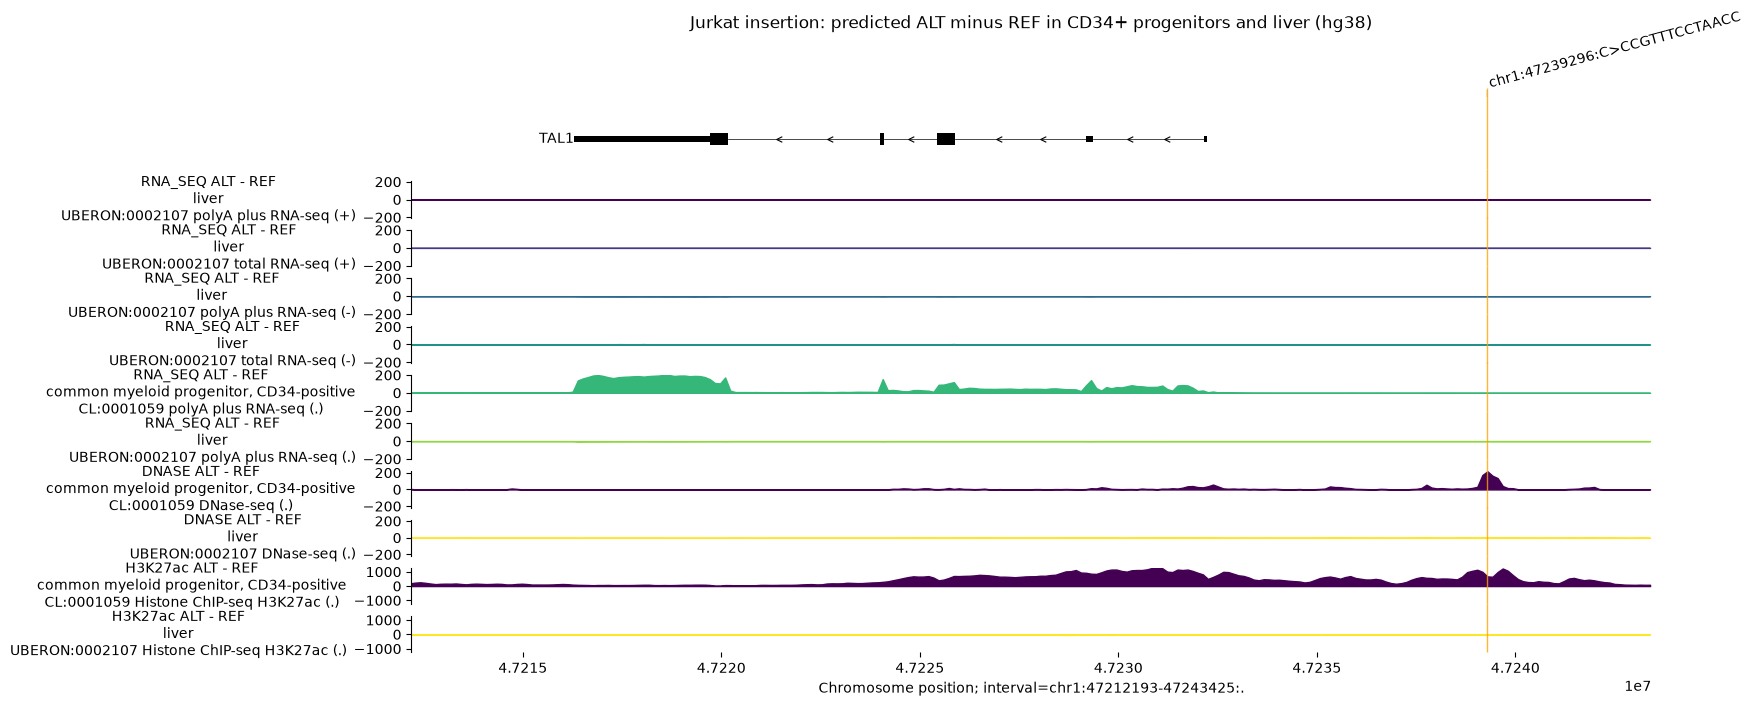

In [5]:
def delta_tracks(ref, alt, label):
    if ref is None or alt is None or ref.num_tracks == 0 or alt.num_tracks == 0:
        raise ValueError(f"Missing supported tracks for {label}.")
    if (ref.interval is None or ref.interval != alt.interval
            or ref.resolution != alt.resolution or ref.values.shape != alt.values.shape
            or not ref.metadata.reset_index(drop=True).equals(alt.metadata.reset_index(drop=True))):
        raise ValueError(f"REF/ALT axes or metadata disagree for {label}.")
    if ref.values.ndim != 2 or not (np.isfinite(ref.values).all() and np.isfinite(alt.values).all()):
        raise ValueError(f"Invalid prediction array for {label}.")
    if ref.values.shape[0] * ref.resolution != ref.interval.width:
        raise ValueError(f"Array width disagrees with genomic interval for {label}.")
    return track_data.TrackData(
        values=alt.values.astype(np.float32) - ref.values.astype(np.float32),
        metadata=ref.metadata.copy(), resolution=ref.resolution, interval=ref.interval,
    )

deltas = {label: delta_tracks(predictions["reference"][label], predictions["alternate"][label], label)
          for label in ("RNA_SEQ", "DNASE", "H3K27ac")}
metadata = pd.concat([t.metadata.assign(modality=label) for label, t in deltas.items()], ignore_index=True)
cols = ["modality", "biosample_name", "ontology_curie", "name", "strand", "Assay title", "histone_mark"]
display(metadata[[c for c in cols if c in metadata]])
for label, tdata in deltas.items():
    for context in CONTEXTS:
        if not tdata.metadata["ontology_curie"].eq(context).any():
            raise ValueError(f"No {label} coverage for {context}; do not interpret as zero.")

plot_start = min(gene_interval.start, variant.reference_interval.start) - 4096
plot_end = max(gene_interval.end, variant.reference_interval.end) + 4096
plot_width = ((plot_end - plot_start + 127) // 128) * 128
plot_interval = genome.Interval(gene_interval.chromosome, plot_start, plot_start + plot_width)
if not plot_interval.contains(variant.reference_interval):
    raise ValueError("Plot window does not include the insertion.")
components = [plot_components.TranscriptAnnotation(transcript_extractor.extract(plot_interval))]
for label, tdata in deltas.items():
    plotted = tdata.change_resolution(128) if tdata.resolution == 1 else tdata
    extent = float(np.max(np.abs(plotted.slice_by_interval(plot_interval, match_resolution=True).values)))
    extent = max(extent, 1e-8)
    components.append(plot_components.Tracks(
        plotted, ylabel_template=label + " ALT - REF\n{biosample_name}\n{name} ({strand})",
        shared_y_scale=True, global_ylims=(-extent, extent), filled=True, track_height=0.6,
    ))
_ = plot_components.plot(
    components, interval=plot_interval, fig_width=16,
    annotations=[plot_components.VariantAnnotation([variant])],
    title="Jurkat insertion: predicted ALT minus REF in CD34+ progenitors and liver (hg38)",
)
plt.show()

## 4. Score the variant and read a tidy table

We explicitly select the **recommended RNA-seq, DNase and histone scorers** from
`RECOMMENDED_VARIANT_SCORERS`. `tidy_scores` preserves the assay metadata.
RNA-seq is gene-centric: filter it to **TAL1**. DNase and H3K27ac scores are
variant-centered and have no target-gene assignment; show them separately.

RNA-seq uses a gene-exon-mask log fold-change score. The recommended DNase and
histone scorers use centered windows and differences of log2 aggregated signals.
Their raw magnitudes are not interchangeable. `quantile_score`, when available,
uses AlphaGenome's calibration background; it is not our local random-insertion rank.

In [6]:
def retain_scores(raw):
    tidy = variant_scorers.tidy_scores([raw], match_gene_strand=True)
    required = {"output_type", "gene_name", "ontology_curie", "raw_score", "track_name", "track_strand"}
    if tidy is None or not required.issubset(tidy.columns):
        raise ValueError("Unexpected tidy score schema.")
    keep = tidy["ontology_curie"].isin(CONTEXTS)
    keep &= tidy["output_type"].ne("RNA_SEQ") | tidy["gene_name"].eq("TAL1")
    if "histone_mark" in tidy:
        keep &= tidy["output_type"].ne("CHIP_HISTONE") | tidy["histone_mark"].eq("H3K27ac")
    tidy = tidy.loc[keep].copy().reset_index(drop=True)
    if tidy.empty or not np.isfinite(tidy["raw_score"].to_numpy(dtype=float)).all():
        raise ValueError("No finite scores returned for the requested contexts.")
    # Use identical serializable column types in live and offline mode.
    for col in ("variant_id", "scored_interval"):
        if col in tidy:
            tidy[col] = tidy[col].map(str)
    # Preserve missing metadata consistently across parquet round trips.
    for col in tidy.columns:
        if col not in ("raw_score", "quantile_score"):
            tidy[col] = tidy[col].astype("string")
    return tidy

def score_one(value, scorer_names=("RNA_SEQ",)):
    scorers = [variant_scorers.RECOMMENDED_VARIANT_SCORERS[name] for name in scorer_names]
    request = {
        "schema": 1, "client_version": CLIENT_VERSION, "assembly": "hg38",
        "interval": interval_spec(interval), "variant": variant_spec(value),
        "scorers": [str(s) for s in scorers], "merge_stranded_gene_tracks": True,
        "contexts": CONTEXTS, "retained_gene": "TAL1", "retained_histone_mark": "H3K27ac",
    }
    # score_variant has no ontology_terms parameter: filter after tidy_scores.
    return cached_bundle("score", request, lambda: retain_scores(model.score_variant(
        interval=interval, variant=value, variant_scorers=scorers,
        organism=dna_client.Organism.HOMO_SAPIENS, merge_stranded_gene_tracks=True,
    )))

def show_scores(frame):
    columns = ["gene_name", "output_type", "biosample_name", "ontology_curie",
               "track_name", "track_strand", "histone_mark", "raw_score", "quantile_score"]
    display(frame[[c for c in columns if c in frame]].reset_index(drop=True))

real_scores = score_one(variant, ("RNA_SEQ", "DNASE", "CHIP_HISTONE"))
tal1_scores = real_scores.loc[real_scores["output_type"].eq("RNA_SEQ") & real_scores["gene_name"].eq("TAL1")]
show_scores(tal1_scores)
show_scores(real_scores.loc[real_scores["output_type"].ne("RNA_SEQ")])

,gene_name,output_type,biosample_name,ontology_curie,track_name,track_strand,histone_mark,raw_score,quantile_score
0,TAL1,RNA_SEQ,liver,UBERON:0002107,UBERON:0002107 polyA plus RNA-seq,.,<NA>,-0.060329,-0.999820
1,TAL1,RNA_SEQ,liver,UBERON:0002107,UBERON:0002107 total RNA-seq,.,<NA>,0.002248,0.886654
2,TAL1,RNA_SEQ,"common myeloid progenitor, CD34-positive",CL:0001059,CL:0001059 polyA plus RNA-seq,.,<NA>,0.588792,0.999998


,gene_name,output_type,biosample_name,ontology_curie,track_name,track_strand,histone_mark,raw_score,quantile_score
0,<NA>,DNASE,"common myeloid progenitor, CD34-positive",CL:0001059,CL:0001059 DNase-seq,.,<NA>,1.892673,0.999469
1,<NA>,DNASE,liver,UBERON:0002107,UBERON:0002107 DNase-seq,.,<NA>,0.252076,0.982731
2,<NA>,CHIP_HISTONE,"common myeloid progenitor, CD34-positive",CL:0001059,CL:0001059 Histone ChIP-seq H3K27ac,.,H3K27ac,1.837438,0.999998
3,<NA>,CHIP_HISTONE,liver,UBERON:0002107,UBERON:0002107 Histone ChIP-seq H3K27ac,.,H3K27ac,0.010365,0.706871


## 5. Does the real insertion stand out from random insertions?

Use exactly the same **TAL1 RNA-seq assay, strand and context** for every variant.
If more than one RNA-seq track is available, the code lists them and uses a
deterministic metadata-based choice. Changing the chosen assay requires live
access or its own matching saved results.

Ranks descend from the largest predicted expression gain. Ties share the best
rank. The table reports the number of background scores greater than or equal
to the real score. A high rank in 20 synthetic controls neither proves
oncogenicity nor measures disease risk.

,track_name,track_strand,ontology_curie,variant_scorer,Assay title,biosample_name
0,CL:0001059 polyA plus RNA-seq,.,CL:0001059,GeneMaskLFCScorer(requested_output=RNA_SEQ),polyA plus RNA-seq,"common myeloid progenitor, CD34-positive"


Ranking/ISM track: {'track_name': 'CL:0001059 polyA plus RNA-seq', 'track_strand': '.', 'ontology_curie': 'CL:0001059', 'variant_scorer': 'GeneMaskLFCScorer(requested_output=RNA_SEQ)'}
Background 1/20 complete.
Background 2/20 complete.
Background 3/20 complete.
Background 4/20 complete.
Background 5/20 complete.
Background 6/20 complete.
Background 7/20 complete.
Background 8/20 complete.
Background 9/20 complete.
Background 10/20 complete.
Background 11/20 complete.
Background 12/20 complete.
Background 13/20 complete.
Background 14/20 complete.
Background 15/20 complete.
Background 16/20 complete.
Background 17/20 complete.
Background 18/20 complete.
Background 19/20 complete.
Background 20/20 complete.


,real_score,rank_descending,total_variants,background_greater,background_tied,background_greater_or_equal,fraction_background_strictly_lower
0,0.588792,1,21,0,0,0,1.0


,name,ALT,group,raw_score
0,Jurkat,CCGTTTCCTAACC,real,0.588792
1,background_10,CCGCTGCGGAAAA,background,0.034958
2,background_13,CTTAATATCTCCG,background,0.029041
3,background_12,CAGTCGACCTACC,background,0.014652
4,background_09,CAGGATATATTTG,background,0.013034
5,background_20,CGACTATCGGCCG,background,0.002890
6,background_16,CTACGCCACACGG,background,-0.003072
7,background_19,CAACTACGAGCTG,background,-0.004949
8,background_04,CTTCGATGCATCT,background,-0.005720
9,background_17,CGCTACACTCTCG,background,-0.006264


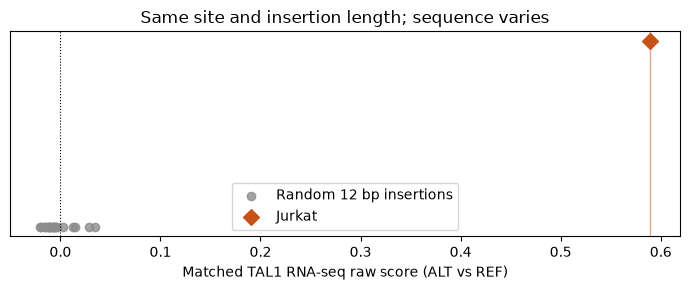

In [7]:
TRACK_KEYS = ["track_name", "track_strand", "ontology_curie", "variant_scorer"]
available = tal1_scores.loc[tal1_scores["ontology_curie"].eq(RANK_CONTEXT)].copy()
if available.empty:
    raise ValueError("No TAL1 RNA-seq score in the chosen ranking context.")
available = available.sort_values(TRACK_KEYS).reset_index(drop=True)
display(available[[c for c in [*TRACK_KEYS, "Assay title", "biosample_name"] if c in available]])
SELECTED_TRACK = {key: available.iloc[0][key] for key in TRACK_KEYS}
print("Ranking/ISM track:", SELECTED_TRACK)

def selected_score(frame):
    keep = frame["output_type"].eq("RNA_SEQ") & frame["gene_name"].eq("TAL1")
    for key, value in SELECTED_TRACK.items():
        keep &= frame[key].eq(value)
    values = frame.loc[keep, "raw_score"].to_numpy(dtype=float)
    if values.size != 1 or not np.isfinite(values).all():
        raise ValueError("Expected exactly one finite, matched TAL1 RNA-seq score.")
    return float(values[0])

def rank_summary(real, background):
    background = np.asarray(background, dtype=float)
    if background.size == 0 or not np.isfinite(background).all() or not np.isfinite(real):
        raise ValueError("Ranking requires a finite nonempty background.")
    greater = int(np.sum(background > real))
    equal = int(np.sum(background == real))
    return {"real_score": real, "rank_descending": 1 + greater,
            "total_variants": int(background.size + 1), "background_greater": greater,
            "background_tied": equal, "background_greater_or_equal": greater + equal,
            "fraction_background_strictly_lower": float(np.mean(background < real))}

real_score = selected_score(real_scores)
rank_rows = [{"name": "Jurkat", "ALT": variant.alternate_bases, "group": "real", "raw_score": real_score}]
for index, candidate in enumerate(background_variants, start=1):
    frame = score_one(candidate)
    rank_rows.append({"name": candidate.name, "ALT": candidate.alternate_bases,
                      "group": "background", "raw_score": selected_score(frame)})
    print(f"Background {index}/{len(background_variants)} complete.")
ranking = pd.DataFrame(rank_rows)
background_scores = ranking.loc[ranking["group"].eq("background"), "raw_score"].to_numpy()
display(pd.DataFrame([rank_summary(real_score, background_scores)]))
display(ranking.sort_values("raw_score", ascending=False).reset_index(drop=True))

fig, ax = plt.subplots(figsize=(7, 3))
ax.scatter(background_scores, np.zeros(len(background_scores)), color="0.55", label="Random 12 bp insertions", alpha=0.8)
ax.scatter([real_score], [0.15], color="#c65418", marker="D", s=65, label="Jurkat")
ax.axvline(real_score, color="#c65418", linewidth=1, alpha=0.5)
ax.axvline(0, color="black", linestyle=":", linewidth=0.8)
ax.set(yticks=[], xlabel="Matched TAL1 RNA-seq raw score (ALT vs REF)", title="Same site and insertion length; sequence varies")
ax.legend(loc="best")
fig.tight_layout()
plt.show()

## 6. Small ISM window: which bases support the predicted gain?

To include **inserted bases**, we explicitly mutate the ALT haplotype rather than
scoring only reference-coordinate SNVs. The window is 21 bases: four reference
bases to the left, the retained anchor, the 12 inserted bases and four reference
bases to the right. Each of its 63 single-base substitutions is represented as
a replacement of the same nine reference bases. Each prediction retains the
same 1 Mb context and the same recommended TAL1 RNA-seq scorer.

For each mutant, subtract the score of the **unmutated expanded ALT haplotype**.
Negative values mean the substitution reduces the model's predicted TAL1 gain
relative to the intact insertion. Compare the equivalent expanded and original
representations before interpreting the matrix.

The short reference sequence is `GTTACGTCT` at
`hg38 chr1:[47239291,47239300)` (0-based), verified against the
[UCSC sequence API](https://api.genome.ucsc.edu/getData/sequence?genome=hg38;chrom=chr1;start=47239291;end=47239300).
It is embedded so this step needs no extra sequence download offline.

Mansour et al. established MYB recruitment experimentally for this insertion.
The plot marks the inserted segment and its `TAAC` core as a **literature-guided
MYB candidate**, not a de novo motif identification or a PWM scan. Ask whether
the model's sensitivity supports that hypothesis.

In [8]:
LOCAL_START = 47_239_291  # 0-based, inclusive.
LOCAL_REF = "GTTACGTCT"  # UCSC hg38 forward-strand sequence, source above.
anchor_index = variant.position - 1 - LOCAL_START
assert anchor_index == 4
assert LOCAL_REF[anchor_index:anchor_index + len(variant.reference_bases)] == variant.reference_bases
LOCAL_ALT = (LOCAL_REF[:anchor_index] + variant.alternate_bases
             + LOCAL_REF[anchor_index + len(variant.reference_bases):])
insert_start = anchor_index + len(variant.reference_bases)
insert_end = insert_start + len(INSERTED)
assert len(LOCAL_ALT) == 21 and LOCAL_ALT[insert_start:insert_end] == INSERTED
expanded_variant = genome.Variant(
    variant.chromosome, LOCAL_START + 1, LOCAL_REF, LOCAL_ALT, name="Jurkat_expanded",
)
expanded_score = selected_score(score_one(expanded_variant))
print("Original insertion score:", real_score)
print("Expanded, equivalent insertion score:", expanded_score)
if not np.isclose(expanded_score, real_score, rtol=1e-3, atol=1e-3):
    raise ValueError("Equivalent variant representations disagree; investigate before interpreting ISM.")

def local_ism_variants():
    rows = []
    for offset, original in enumerate(LOCAL_ALT):
        for base in "ACGT":
            if base == original:
                continue
            mutated = LOCAL_ALT[:offset] + base + LOCAL_ALT[offset + 1:]
            value = genome.Variant(
                variant.chromosome, LOCAL_START + 1, LOCAL_REF, mutated,
                name=f"Jurkat_ism_{offset:02d}_{base}",
            )
            rows.append((offset, original, base, value))
    return rows

ism_rows = []
ism_candidates = local_ism_variants()
assert len(ism_candidates) == 63
for number, (offset, original, base, value) in enumerate(ism_candidates, start=1):
    score = selected_score(score_one(value))
    ism_rows.append({"alt_offset": offset, "original_base": original, "mutant_base": base,
                     "raw_score": score, "delta_vs_intact_alt": score - expanded_score})
    if number % 12 == 0 or number == len(ism_candidates):
        print(f"ISM {number}/{len(ism_candidates)} complete.")
ism_table = pd.DataFrame(ism_rows)

Original insertion score: 0.5887924432754517
Expanded, equivalent insertion score: 0.5887924432754517
ISM 12/63 complete.
ISM 24/63 complete.
ISM 36/63 complete.
ISM 48/63 complete.
ISM 60/63 complete.
ISM 63/63 complete.


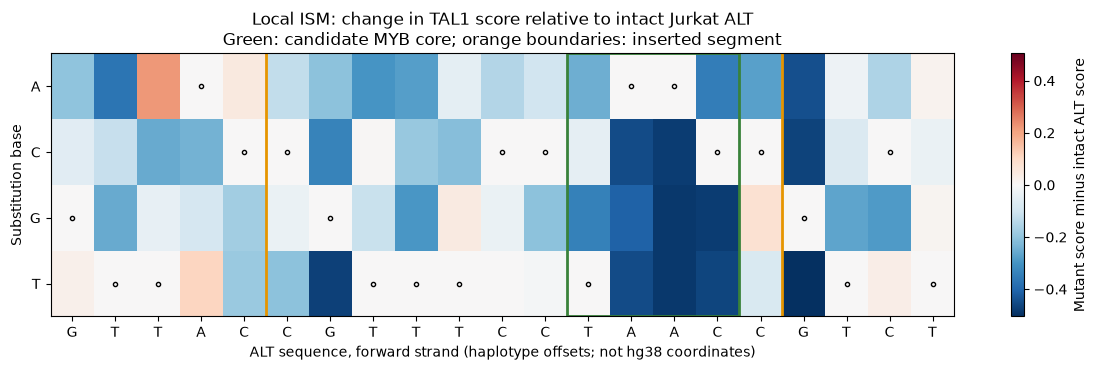

Orange boundaries: inserted segment. Circles: unchanged bases (zero by definition).
Green outline: literature-guided core; ISM alone does not identify a transcription factor.


,alt_offset,original_base,mutant_base,raw_score,delta_vs_intact_alt
0,17,G,T,0.083747,-0.505046
1,14,A,G,0.101190,-0.487603
2,14,A,T,0.103193,-0.485600
3,15,C,G,0.107959,-0.480833
4,14,A,C,0.110267,-0.478526
5,6,G,T,0.117679,-0.471113
6,17,G,C,0.122287,-0.466505
7,15,C,T,0.124811,-0.463982
8,13,A,T,0.135583,-0.453209
9,13,A,C,0.138203,-0.450590


In [9]:
matrix = np.zeros((4, len(LOCAL_ALT)), dtype=float)
for row in ism_table.itertuples():
    matrix["ACGT".index(row.mutant_base), row.alt_offset] = row.delta_vs_intact_alt
if not np.isfinite(matrix).all():
    raise ValueError("ISM matrix contains non-finite values.")
limit = max(float(np.max(np.abs(matrix))), 1e-8)
fig, ax = plt.subplots(figsize=(12, 3.8))
im = ax.imshow(matrix, cmap="RdBu_r", vmin=-limit, vmax=limit, aspect="auto")
ax.set(yticks=range(4), yticklabels=list("ACGT"), xticks=range(len(LOCAL_ALT)),
       xticklabels=list(LOCAL_ALT), ylabel="Substitution base",
       xlabel="ALT sequence, forward strand (haplotype offsets; not hg38 coordinates)",
       title="Local ISM: change in TAL1 score relative to intact Jurkat ALT\nGreen: candidate MYB core; orange boundaries: inserted segment")
ax.axvline(insert_start - 0.5, color="#e69500", linewidth=2)
ax.axvline(insert_end - 0.5, color="#e69500", linewidth=2)
ax.plot(range(len(LOCAL_ALT)), ["ACGT".index(base) for base in LOCAL_ALT],
        "o", markersize=3, markerfacecolor="none", markeredgecolor="black")
core = LOCAL_ALT.find("TAAC", insert_start, insert_end)
if core >= 0:
    ax.axvspan(core - 0.5, core + 3.5, facecolor="none", edgecolor="#39823a", linewidth=2)
fig.colorbar(im, ax=ax, label="Mutant score minus intact ALT score")
fig.tight_layout()
plt.show()
print("Orange boundaries: inserted segment. Circles: unchanged bases (zero by definition).")
print("Green outline: literature-guided core; ISM alone does not identify a transcription factor.")
display(ism_table.sort_values("delta_vs_intact_alt").head(10).reset_index(drop=True))

## 7. Discuss the evidence and its limits

1. Do RNA-seq, DNase and H3K27ac changes tell a consistent regulatory story?
   Which changes occur near the insertion and which near TAL1?
2. Where does Jurkat rank among the random insertions on the matched assay?
   How might that change with more controls or GC-matched controls?
3. Which substitutions reduce the predicted gain? Do they overlap the reported
   MYB-binding region? What experiment would distinguish a MYB mechanism from
   another sequence-dependent effect?
4. Does liver show the same response as CD34+ progenitors? What can we conclude
   about Jurkat when the predicted cell type is not Jurkat?
5. What evidence would be needed to call a previously unknown variant oncogenic?

**Limits to keep in mind:**

- **Cell-type coverage:** available assays are uneven, and these contexts do not
  reproduce patient cells, malignant state, MYB abundance or every cofactor.
- **Indels:** allele representation, sequence alignment and fixed input windows
  affect interpretation. This local ISM tests substitutions on one insertion
  haplotype; it does not exhaust indel lengths, haplotypes or mechanisms.
- **3D effects:** this exercise does not infer variant-induced chromatin contacts
  or a physical enhancer–promoter loop. Interval contact maps in Exercise 1 do
  not establish that this variant changes 3D structure. The pinned client lists
  a contact-map scorer, but it is not used or validated in this exercise.
- **Prediction versus mechanism:** accessibility and H3K27ac do not prove an
  enhancer target. ISM is model sensitivity, not experimental mutagenesis or
  direct evidence of MYB binding. A short motif core is not TF-specific.
- **Benchmark scope:** local synthetic controls are illustrative. They are not
  a clinical validation set, and the API quantile is not a probability of cancer.

Write a two-sentence conclusion: one sentence about the model's regulatory
evidence, and one about what remains untested. Check the primary study after
forming your interpretation.

## 8. Try it yourself: another Mansour/Smith variant

Choose a different entry below and enable the final cell. The hg38 alleles come
from the official TAL1 example's curated table, which cites Mansour (2014) and
Smith (2023). Keep the gene-centered 1 Mb interval and compare the same assay.

New variants need live access unless their own results were generated. These
alleles include replacement-style indels, so do not run the pure-insertion
background generator or the Jurkat-specific ISM on them without adapting it.

In [10]:
other_variants = pd.DataFrame([
    {"ID": "MOLT-3", "CHROM": "chr1", "POS": 47_239_296, "REF": "C", "ALT": "ACC", "study": "Mansour_2014"},
    {"ID": "Patient_1", "CHROM": "chr1", "POS": 47_239_296, "REF": "C", "ALT": "AACG", "study": "Mansour_2014"},
    {"ID": "Smith_UPNT802", "CHROM": "chr1", "POS": 47_212_072, "REF": "T", "ALT": "TGGGTAAACCGTCTGTTCAGCG", "study": "Smith_2023"},
    {"ID": "Smith_UPNT613", "CHROM": "chr1", "POS": 47_212_074, "REF": "G", "ALT": "GAACGTT", "study": "Smith_2023"},
])
display(other_variants)

RUN_TRY_IT = False
TRY_VARIANT_ID = "Smith_UPNT613"
if RUN_TRY_IT:
    matches = other_variants.loc[other_variants["ID"].eq(TRY_VARIANT_ID)]
    if len(matches) != 1:
        raise ValueError("Select exactly one ID from the displayed table.")
    row = matches.iloc[0]
    other = genome.Variant(str(row.CHROM), int(row.POS), row.REF, row.ALT, name=row.ID)
    if not interval.contains(other.reference_interval):
        raise ValueError("Selected variant is outside the prediction interval.")
    other_scores = score_one(other, ("RNA_SEQ", "DNASE", "CHIP_HISTONE"))
    show_scores(other_scores)
    print("Matched TAL1 score:", selected_score(other_scores))
    print("Jurkat matched TAL1 score:", real_score)
    print("Discuss the different site, allele length and regulatory context.")
else:
    print("Optional: choose TRY_VARIANT_ID, set RUN_TRY_IT = True, and rerun this cell.")

,ID,CHROM,POS,REF,ALT,study
0,MOLT-3,chr1,47239296,C,ACC,Mansour_2014
1,Patient_1,chr1,47239296,C,AACG,Mansour_2014
2,Smith_UPNT802,chr1,47212072,T,TGGGTAAACCGTCTGTTCAGCG,Smith_2023
3,Smith_UPNT613,chr1,47212074,G,GAACGTT,Smith_2023


Optional: choose TRY_VARIANT_ID, set RUN_TRY_IT = True, and rerun this cell.


## Sources

This workshop exercise adapts the analysis design of Google DeepMind's
[Example analysis workflow: TAL1 locus](https://www.alphagenomedocs.com/colabs/v1/example_analysis_workflow.html)
([source pinned to v0.10.0](https://github.com/google-deepmind/alphagenome/blob/v0.10.0/colabs/v1/example_analysis_workflow.ipynb)).
The wording, anchored-background generator, ranking, cache handling, and explicit ALT-haplotype ISM were developed for this workshop.

AlphaGenome software: Copyright Google LLC, licensed under
[Apache License 2.0](https://github.com/google-deepmind/alphagenome/blob/v0.10.0/LICENSE).
Its repository separately licenses examples and documentation under
[CC BY 4.0](https://creativecommons.org/licenses/by/4.0/), as stated in its
[license notice](https://github.com/google-deepmind/alphagenome/blob/v0.10.0/README.md#license).

- Mansour et al. (2014). *An oncogenic super-enhancer formed through somatic
  mutation of a noncoding intergenic element.* Science 346:1373–1377.
  [doi:10.1126/science.1259037](https://doi.org/10.1126/science.1259037).
- Smith et al. (2023). *TAL1 activation in T-cell acute lymphoblastic leukemia:
  a novel oncogenic 3′ neo-enhancer.* Haematologica.
  [doi:10.3324/haematol.2022.281583](https://doi.org/10.3324/haematol.2022.281583).
- UCSC Genome Browser: short hg38 reference context retrieved using the
  sequence API linked above (checked 23 October 2026).